# CatBoost: проверяемый прогноз денежных потоков
Только CatBoost и исходный архив кейса. Никаких внешних датасетов, гибрида или ансамбля.
Все таблицы и графики ниже получаются при выполнении; старые результаты не подставляются.
Запускайте ячейки последовательно. В Colab: Runtime → Run all; локально — из analytics/.
Оцениваем перенос на новые компании и в будущее: 5 фолдов компаний и временная граница.
По умолчанию цель — полный фактический банковский остаток из кейса.
CFG['target']='operational' — отдельный эксперимент без будущих денег владельца,
собственных переводов и финансирования; его результаты нельзя смешивать с основными.



In [1]:
import importlib.util
import json
import os
import sys
import subprocess
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
required = {'catboost': 'catboost', 'numpy': 'numpy', 'pandas': 'pandas',
            'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib', 'scipy': 'scipy'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)
import hashlib
import re
import time
import zipfile
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
if not IN_COLAB:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor, CatBoostClassifier, Pool
from scipy.stats import norm
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
    roc_curve, precision_recall_curve)
from sklearn.model_selection import StratifiedGroupKFold



## 1. Настройки и воспроизводимость
Для быстрого дымового запуска задайте CB_CFG='{"iterations":80,"eval_cutoffs":2}'.
Не выдавайте дымовой запуск за полный эксперимент. Не меняйте настройки после просмотра теста.



In [2]:
CFG = dict(horizon=30, eval_cutoffs=12, eval_step=5, min_history=60, train_step=6,
           train_horizons=[1,2,3,5,7,10,14,20,25,30], n_folds=5, val_frac=.15,
           iterations=800, learning_rate=.06, depth=5, l2_leaf_reg=5., early_stopping=80,
           threads=4, seed=7, bootstrap=300, target='actual', max_companies=None,
           quantiles=[.05,.1,.2,.3,.5,.7,.8,.9,.95], day_risk_threshold=.2)
CFG.update(json.loads(os.environ.get('CB_CFG', '{}')))
assert CFG['target'] in ('operational', 'actual')
assert CFG['horizon'] == 30 and CFG['n_folds'] >= 2
H, QS = CFG['horizon'], CFG['quantiles']
OUT = Path(os.environ.get('CB_OUT', 'mentor_catboost_output')).resolve()
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'models').mkdir(exist_ok=True)
STARTED = time.time()
plt.rcParams.update({'figure.figsize': (9,4), 'axes.spines.top':False,
                    'axes.spines.right':False, 'figure.dpi':110, 'axes.grid':True,
                    'grid.alpha':.2, 'font.size':10})
print(json.dumps(CFG, ensure_ascii=False, indent=2))



{
  "horizon": 30,
  "eval_cutoffs": 12,
  "eval_step": 5,
  "min_history": 60,
  "train_step": 6,
  "train_horizons": [
    1,
    2,
    3,
    5,
    7,
    10,
    14,
    20,
    25,
    30
  ],
  "n_folds": 5,
  "val_frac": 0.15,
  "iterations": 800,
  "learning_rate": 0.06,
  "depth": 5,
  "l2_leaf_reg": 5.0,
  "early_stopping": 80,
  "threads": 4,
  "seed": 7,
  "bootstrap": 300,
  "target": "actual",
  "max_companies": null,
  "quantiles": [
    0.05,
    0.1,
    0.2,
    0.3,
    0.5,
    0.7,
    0.8,
    0.9,
    0.95
  ],
  "day_risk_threshold": 0.2
}


## 2. Исходный архив
Файлы читаются прямо из ZIP, ничего не исполняется и не распаковывается.
Локально можно задать CASE_ZIP. В Colab появится диалог загрузки архива.



In [3]:
archive_path = os.environ.get('CASE_ZIP', '')
if not archive_path:
    candidates = [Path('cashflow_dataset_participants.zip'),
        Path('/content/cashflow_dataset_participants.zip')]
    archive_path = next((str(p) for p in candidates if p.is_file()), '')
if not archive_path and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    archive_path = next((name for name in uploaded if name.lower().endswith('.zip')), '')
assert archive_path and Path(archive_path).is_file(), 'Укажите CASE_ZIP: путь к архиву кейса'
archive_sha256 = hashlib.sha256(Path(archive_path).read_bytes()).hexdigest()
with zipfile.ZipFile(archive_path) as z:
    def member(suffix):
        hits = [name for name in z.namelist() if name == suffix or name.endswith('/'+suffix)]
        assert len(hits) == 1, 'Не найден однозначный файл '+suffix
        return hits[0]
    with z.open(member('all_operations.csv')) as f:
        RAW = pd.read_csv(f, sep=';', encoding='utf-8-sig', dtype=str, keep_default_na=False)
    with z.open(member('companies.csv')) as f:
        COMPANIES = pd.read_csv(f, sep=';', encoding='utf-8-sig', dtype=str, keep_default_na=False)
RAW['operation_date'] = pd.to_datetime(RAW['operation_date'], format='%Y-%m-%d', errors='raise')
for col in ('amount','balance_eod'):
    RAW[col] = pd.to_numeric(RAW[col], errors='raise')
assert np.isfinite(RAW[['amount','balance_eod']].to_numpy()).all()
RAW['direction'] = RAW['direction'].map({'Поступление':'in','Списание':'out'})
assert RAW['direction'].notna().all() and RAW['amount'].gt(0).all()
RAW['signed'] = np.where(RAW['direction'].eq('in'), RAW['amount'], -RAW['amount'])
RAW = RAW.sort_values(['company_id','operation_date','operation_id']).reset_index(drop=True)
INDUSTRY = dict(zip(COMPANIES['company_id'], COMPANIES.get('industry', pd.Series('unknown', index=COMPANIES.index))))
# Даты рабочего календаря известны извне; значения будущих операций в признаки не попадают.
CALENDAR = pd.DatetimeIndex(sorted(RAW['operation_date'].unique()))
print('Компаний:',RAW['company_id'].nunique(),'операций:',len(RAW),'период:',CALENDAR.min().date(),CALENDAR.max().date())



Компаний: 150 операций: 222420 период: 2024-10-01 2026-09-30


## 3. Причинная подготовка данных
Фиксированные правила ниже только выделяют исключаемые финансовые потоки.
История контрагента и ML-категоризатор не используются: будущие назначения не обучают признаки.
Лишний дубль подтверждается остатком текущего и предыдущего дня; дни после разрыва
истории отмечаются. Окна с такой дырой внутри целевого горизонта не оцениваются.



In [4]:
IN_RULES = [('retail',r'эквайринг|\bСБП\b|взнос наличных|инкасс|договору? оферты.*за период|маркетплейс'),
    ('owner',r'займ|задолженности по овердрафту|уставн'),
    ('financing',r'выдач[аи] кредит|предоставлени[ея] кредит|зачислени[ея] кредит|транш'),
    ('transfer',r'собственн|с расчетного счета в')]
OUT_RULES = [('operating',r'единый налог|\bЕНП\b|налогов|страховые взносы|пени|штраф|исполнительн|заработн|зарплат|отпускн|больничн|ГПХ|самозанят'),
    ('owner',r'дивиденд|личн|на счет физического лица|займа учредител|подотчет'),
    ('operating',r'комисси|POS-терминал|ведени[ея] счета|расчетно-кассов'),
    ('financing',r'кредит|овердрафт|процент'), ('operating',r'лизинг|аренд|электроэнерг|водоснабж'),
    ('transfer',r'собственн')]
RULES = {d:[(c,re.compile(rx,re.I)) for c,rx in rules] for d,rules in [('in',IN_RULES),('out',OUT_RULES)]}
def financial_role(direction, purpose):
    for category,rx in RULES[direction]:
        if rx.search(str(purpose)):
            return category
    return 'operating'
def operational_flow(ops, dates):
    mask = ~ops['financial_role'].isin(['owner','transfer','financing']) if CFG['target']=='operational' else np.ones(len(ops),bool)
    return ops.loc[mask].groupby('operation_date')['signed'].sum().reindex(dates, fill_value=0.)
def prepare_company(frame):
    ops = frame.copy()
    dup_cols = ['operation_date','amount','direction','counterparty_inn','counterparty_name','payment_purpose']
    candidate = ops.duplicated(dup_cols, keep='first')
    g = ops.groupby('operation_date')
    daily = pd.DataFrame({'balance':g['balance_eod'].first(),'net':g['signed'].sum(),
        'dup_signed':ops[candidate].groupby('operation_date')['signed'].sum()}).fillna({'dup_signed':0.})
    residual = daily['balance']-daily['balance'].shift()-daily['net']
    confirmed = daily.index[daily['dup_signed'].ne(0)&(residual+daily['dup_signed']).abs().lt(.01)]
    duplicate = candidate & ops['operation_date'].isin(confirmed)
    ops = ops[~duplicate].copy()
    ops['financial_role'] = [financial_role(d,p) for d,p in zip(ops['direction'],ops['payment_purpose'])]
    dates = CALENDAR[(CALENDAR>=ops['operation_date'].min())&(CALENDAR<=ops['operation_date'].max())]
    g = ops.groupby('operation_date')
    bal = g['balance_eod'].first().reindex(dates)
    net = g['signed'].sum().reindex(dates, fill_value=0.)
    present = np.flatnonzero(bal.notna().to_numpy())
    after_gap = np.zeros(len(dates),bool)
    for a,b in zip(present[:-1],present[1:]):
        if b-a-1>=3 and abs(float(bal.iloc[b]-bal.iloc[a]-net.iloc[b]))>.01:
            after_gap[b] = True
    return dict(dates=dates, balance=bal.ffill().to_numpy(float), flow=operational_flow(ops,dates),
                net=net.to_numpy(float), after_gap=after_gap, duplicates=int(duplicate.sum()))
PREPS = {str(cid):prepare_company(g) for cid,g in RAW.groupby('company_id',sort=True)}
if CFG['max_companies']:
    PREPS = dict(list(PREPS.items())[:int(CFG['max_companies'])])
print('Подготовлено:',len(PREPS),'компаний; дублей:',sum(p['duplicates'] for p in PREPS.values()))



Подготовлено: 150 компаний; дублей: 20


## 4. Признаки и накопленная цель
Одна строка = компания × отсечка × горизонт h. y — сумма будущего потока / масштаб.
Все средние, лаги и масштаб вычисляются только по префиксу до отсечки.
Остаток = известный остаток + масштаб × прогноз накопленного потока.



In [5]:
NON_FEATURES = ['y','company','cutoff','scale']
CAT_FEATURES = ['industry','target_dow','source']
def make_cum_rows(flow, industry, company, positions=None, horizons=None, max_target_date=None):
    vals,dates = flow.to_numpy(float),flow.index
    cum = np.r_[0.,np.cumsum(vals)]
    key = dates.year*12+dates.month
    tax = pd.Series(dates.day>=28).groupby(key).transform(lambda s:s&~s.shift(fill_value=False).cummax()).to_numpy()
    hs = horizons if horizons is not None else list(range(1,H+1))
    ts = positions if positions is not None else range(CFG['min_history'],len(vals)-H,CFG['train_step'])
    rows = []
    for t in ts:
        sc = max(float(np.abs(vals[max(0,t-59):t+1]).mean()),1.)
        hist = vals[:t+1]/sc
        base = dict(industry=str(industry),source='case',company=str(company),cutoff=dates[t],scale=sc,
            mean_5=float(hist[-5:].mean()),mean_20=float(hist[-20:].mean()),mean_60=float(hist[-60:].mean()),
            std_20=float(hist[-20:].std()),share_pos_20=float((hist[-20:]>0).mean()),cutoff_dom=int(dates[t].day))
        for h in hs:
            end=t+h
            if end>=len(vals):
                continue
            if max_target_date is not None and dates[end]>=max_target_date:
                continue
            lag=21*int(np.ceil(h/21))
            rows.append(dict(base,h=int(h),target_dow=str(dates[end].dayofweek),target_dom=int(dates[end].day),
                target_month=int(dates[end].month),n_tax_days=int(tax[t+1:end+1].sum()),mean60_x_h=base['mean_60']*h,
                lag1=(cum[end-lag+1]-cum[t-lag+1])/sc if t-lag>=0 else np.nan,
                lag2=(cum[end-lag-20]-cum[t-lag-20])/sc if t-lag-21>=0 else np.nan,
                y=(cum[end+1]-cum[t+1])/sc))
    return pd.DataFrame(rows)
def make_windows(cids, before=None):
    result=[]
    for cid in cids:
        p=PREPS[cid]; n=len(p['dates'])
        last=n-1 if before is None else int(p['dates'].searchsorted(before))-1
        for k in range(CFG['eval_cutoffs']):
            pos=last-H-k*CFG['eval_step']
            if pos<CFG['min_history']:
                break
            if p['after_gap'][pos+1:pos+1+H].any():
                continue
            target=(p['balance'][pos+1:pos+1+H] if CFG['target']=='actual'
                    else p['balance'][pos]+np.cumsum(p['flow'].to_numpy()[pos+1:pos+1+H]))
            result.append(dict(company=cid,pos=pos,cutoff=p['dates'][pos],bal0=float(p['balance'][pos]),
                actual=target, actual_cash=p['balance'][pos+1:pos+1+H],
                dates=p['dates'][pos+1:pos+1+H],gap_actual=bool((target<0).any()),ongoing=bool(p['balance'][pos]<0)))
    return result
IDS=np.array(sorted(PREPS))
W=pd.DataFrame(make_windows(IDS))
assert len(W)>0,'Недостаточно истории для проверки'
EVAL_START=W['cutoff'].min()
STRATA=np.array([INDUSTRY.get(c,'unknown') for c in IDS])
assert len(IDS)>=CFG['n_folds']*3, 'Слишком мало компаний для независимых train/validation/test'
splitter=StratifiedGroupKFold(n_splits=CFG['n_folds'],shuffle=True,random_state=CFG['seed'])
FOLD_OF={c:f for f,(_,te) in enumerate(splitter.split(IDS,STRATA,groups=IDS)) for c in IDS[te]}
W['fold']=W['company'].map(FOLD_OF)
print('Окон:',len(W),'первая тестовая отсечка:',EVAL_START.date())



Окон: 1652 первая тестовая отсечка: 2025-06-20


## 5. Обучение: тест не участвует в выборе модели или порога
Для каждого outer fold: test — новые компании; validation — отдельные компании.
Обучающие цели и validation-окна заканчиваются раньше EVAL_START.
Early stopping и порог используют только validation. Финальные метрики — только test.
RMSE даёт средний точечный прогноз, не медиану. MultiQuantile отдельно даёт P10/P50/P90.
Три головы одного алгоритма: RMSE для остатка, MultiQuantile для интервалов,
CatBoostClassifier для риска окна. Их прогнозы не усредняются в ансамбль.



In [6]:
def X(rows):
    return rows.drop(columns=[c for c in NON_FEATURES if c in rows])
def train_rows(cids):
    parts=[]
    for cid in cids:
        p=PREPS[cid]
        rows=make_cum_rows(p['flow'],INDUSTRY.get(cid,'unknown'),cid,
            horizons=CFG['train_horizons'],max_target_date=EVAL_START)
        if len(rows):
            # Удаляем цели, которые пересекают наблюдаемую дыру; исторические признаки не используют будущее.
            index=p['dates'].get_indexer(rows['cutoff'])
            keep=[not p['after_gap'][t+1:t+int(h)+1].any() for t,h in zip(index,rows['h'])]
            parts.append(rows[np.asarray(keep)])
    assert parts,'Нет обучающих строк'
    return pd.concat(parts,ignore_index=True)
def probability_below_zero(q):
    result=[]
    for values in q:
        if values[0]<=0<=values[-1]:
            p=float(np.interp(0,values,QS))
        else:
            sigma=max(float(values[-1]-values[0])/(2*norm.ppf(QS[-1])),1e-9)
            p=float(norm.cdf(-values[QS.index(.5)]/sigma))
            p=min(p,QS[0]) if 0<values[0] else max(p,QS[-1])
        result.append(p)
    return np.clip(result,0,1)
def predict_windows(windows,m_mean,m_q):
    predictions=[]
    for w in windows:
        p=PREPS[w['company']]
        rows=make_cum_rows(p['flow'],INDUSTRY.get(w['company'],'unknown'),w['company'],positions=[w['pos']])
        assert len(rows)==H
        sc=float(rows['scale'].iloc[0])
        mean=w['bal0']+sc*np.asarray(m_mean.predict(X(rows)))
        q=w['bal0']+sc*np.sort(np.asarray(m_q.predict(X(rows))),axis=1)
        prob=probability_below_zero(q)
        predictions.append(dict(mean=mean,q=q,prob=prob,quantile_score=float(prob.max()),scale=sc))
    return predictions
def _risk_features(windows):
    rows=[]
    for w in windows:
        p=PREPS[w['company']]; pos=w['pos']
        r=make_cum_rows(p['flow'],INDUSTRY.get(w['company'],'unknown'),w['company'],
            positions=[pos],horizons=[H])
        assert len(r)==1
        sc=float(r['scale'].iloc[0]); f=X(r).copy()
        f['balance_scaled']=w['bal0']/sc
        f['negative_balance_share_60']=float((p['balance'][max(0,pos-59):pos+1]<0).mean())
        rows.append(f)
    assert rows,'Нет окон для классификатора риска'
    return pd.concat(rows,ignore_index=True)
OOF=[None]*len(W); FOLD_LOG=[]; IMPORTANCES=[]; CURVES={}; MODELS={}
for fold in range(CFG['n_folds']):
    t0=time.time(); train_ids=[c for c in IDS if FOLD_OF[c]!=fold]
    rng=np.random.default_rng(CFG['seed']+fold)
    val_ids=set(rng.choice(train_ids,size=max(2,int(len(train_ids)*CFG['val_frac'])),replace=False))
    fit_ids=[c for c in train_ids if c not in val_ids]
    assert not(set(fit_ids)&val_ids) and not(set(train_ids)&set(IDS[[FOLD_OF[c]==fold for c in IDS]]))
    tr,va=train_rows(fit_ids),train_rows(sorted(val_ids))
    FEATURES=list(X(tr).columns)
    params=dict(iterations=CFG['iterations'],depth=CFG['depth'],learning_rate=CFG['learning_rate'],
        l2_leaf_reg=CFG['l2_leaf_reg'],random_seed=CFG['seed'],thread_count=CFG['threads'],
        early_stopping_rounds=CFG['early_stopping'],use_best_model=True,verbose=False,allow_writing_files=False)
    m_mean=CatBoostRegressor(loss_function='RMSE',**params)
    m_q=CatBoostRegressor(loss_function='MultiQuantile:alpha='+','.join(map(str,QS)),**params)
    train_pool=Pool(X(tr),tr['y'],cat_features=CAT_FEATURES)
    val_pool=Pool(X(va),va['y'],cat_features=CAT_FEATURES)
    m_mean.fit(train_pool,eval_set=val_pool); m_q.fit(train_pool,eval_set=val_pool)
    validation=make_windows(sorted(val_ids),before=EVAL_START)
    risk_train=[w for w in make_windows(fit_ids,before=EVAL_START) if not w['ongoing']]
    risk_val=[w for w in validation if not w['ongoing']]
    ry=np.array([w['gap_actual'] for w in risk_train],int)
    assert len(np.unique(ry))==2,'В train классификатора нужны оба класса'
    risk_x=_risk_features(risk_train); RISK_FEATURES=list(risk_x.columns)
    vy=np.array([w['gap_actual'] for w in risk_val],bool)
    assert len(vy),'Нет validation окон классификатора'
    risk_params=dict(params,depth=4)
    risk_metric='AUC' if len(np.unique(vy))==2 else 'Logloss'
    m_risk=CatBoostClassifier(loss_function='Logloss',eval_metric=risk_metric,
        auto_class_weights='Balanced',**risk_params)
    m_risk.fit(Pool(risk_x,ry,cat_features=CAT_FEATURES),
        eval_set=Pool(_risk_features(risk_val),vy.astype(int),cat_features=CAT_FEATURES))
    vs=m_risk.predict_proba(_risk_features(risk_val))[:,1]
    keep=[i for i,w in enumerate(validation) if not w['ongoing']]
    if len(vy) and len(np.unique(vy))==2:
        threshold=float(max(np.arange(.05,.951,.05),key=lambda t:f1_score(vy,vs>=t,zero_division=0)))
        threshold_note='максимум F1 только validation до EVAL_START'
    else:
        threshold=.5; threshold_note='нет двух классов validation: заранее заданный 0.5'
    idx=np.flatnonzero(W['fold'].eq(fold))
    test_windows=[W.iloc[i].to_dict() for i in idx]
    test_scores=m_risk.predict_proba(_risk_features(test_windows))[:,1]
    for i,pred,risk_score in zip(idx,predict_windows(test_windows,m_mean,m_q),test_scores):
        OOF[i]=dict(pred,score=float(risk_score),threshold=threshold)
    m_mean.save_model(str(OUT/'models'/f'fold_{fold}_mean.cbm'))
    m_q.save_model(str(OUT/'models'/f'fold_{fold}_quantiles.cbm'))
    m_risk.save_model(str(OUT/'models'/f'fold_{fold}_risk.cbm'))
    MODELS[fold]=(m_mean,m_q,m_risk)
    CURVES[fold]=m_mean.get_evals_result()
    IMPORTANCES.append(m_mean.get_feature_importance())
    FOLD_LOG.append(dict(fold=fold,train_companies=len(fit_ids),validation_companies=len(val_ids),
        test_companies=int(W.loc[idx,'company'].nunique()),train_rows=len(tr),validation_rows=len(va),
        validation_windows=len(keep),validation_positives=int(vy.sum()),threshold=threshold,
        threshold_note=threshold_note,trees_rmse=m_mean.tree_count_,trees_quantile=m_q.tree_count_,
        risk_train_windows=len(ry),risk_train_positives=int(ry.sum()),trees_risk=m_risk.tree_count_,
        seconds=round(time.time()-t0,2)))
    print(FOLD_LOG[-1])
assert all(p is not None for p in OOF)
FOLDS=pd.DataFrame(FOLD_LOG)
print(FOLDS.to_string(index=False))



{'fold': 0, 'train_companies': 102, 'validation_companies': 18, 'test_companies': 28, 'train_rows': 14280, 'validation_rows': 2956, 'validation_windows': 190, 'validation_positives': 4, 'threshold': 0.4, 'threshold_note': 'максимум F1 только validation до EVAL_START', 'trees_rmse': 125, 'trees_quantile': 261, 'risk_train_windows': 954, 'risk_train_positives': 21, 'trees_risk': 168, 'seconds': 42.8}
{'fold': 1, 'train_companies': 102, 'validation_companies': 18, 'test_companies': 28, 'train_rows': 15132, 'validation_rows': 2625, 'validation_windows': 172, 'validation_positives': 4, 'threshold': 0.55, 'threshold_note': 'максимум F1 только validation до EVAL_START', 'trees_rmse': 232, 'trees_quantile': 297, 'risk_train_windows': 1005, 'risk_train_positives': 17, 'trees_risk': 1, 'seconds': 44.54}
{'fold': 2, 'train_companies': 102, 'validation_companies': 18, 'test_companies': 30, 'train_rows': 13972, 'validation_rows': 2267, 'validation_windows': 154, 'validation_positives': 0, 'threshol

D:\!finance\ledokol_tmp\analytics\catboost_mentor_ready.ipynb:24: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "import importlib.util\n",
D:\!finance\ledokol_tmp\analytics\catboost_mentor_ready.ipynb:24: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "import importlib.util\n",
D:\!finance\ledokol_tmp\analytics\catboost_mentor_ready.ipynb:24: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "import importlib.util\n",
D:\!finance\ledokol_tmp\analytics\catboost_mentor_ready.ipynb:24: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "import importlib.util\n",
D:\!finance\ledokol_tmp\analytics\catboost_mentor_ready.ipynb:24: Pandas4Warning: Timestamp.dayofweek is deprecated 

## 6. Риск: precision, recall, F1, confusion matrix, ROC/PR, Brier
Единица оценки — компания × отсечка × следующие 30 рабочих дней, не отдельный эпизод.
Окна с уже отрицательным начальным остатком исключены из раннего предупреждения.
score — вероятность класса CatBoostClassifier: отрицательный остаток хотя бы раз за окно.
Балансировка классов может искажать калибровку вероятности; Brier это проверяет.



{
  "precision": 0.17117117117117117,
  "recall": 0.5428571428571428,
  "f1": 0.2602739726027397,
  "accuracy": 0.9322033898305084,
  "roc_auc": 0.8574912891986063,
  "pr_auc": 0.245838643483274,
  "brier": 0.053334744240772565,
  "windows": 1593,
  "positives": 35,
  "positive_rate": 0.02197112366603892,
  "confusion_matrix": [
    [
      1466,
      92
    ],
    [
      16,
      19
    ]
  ],
  "excluded_ongoing": 59
}


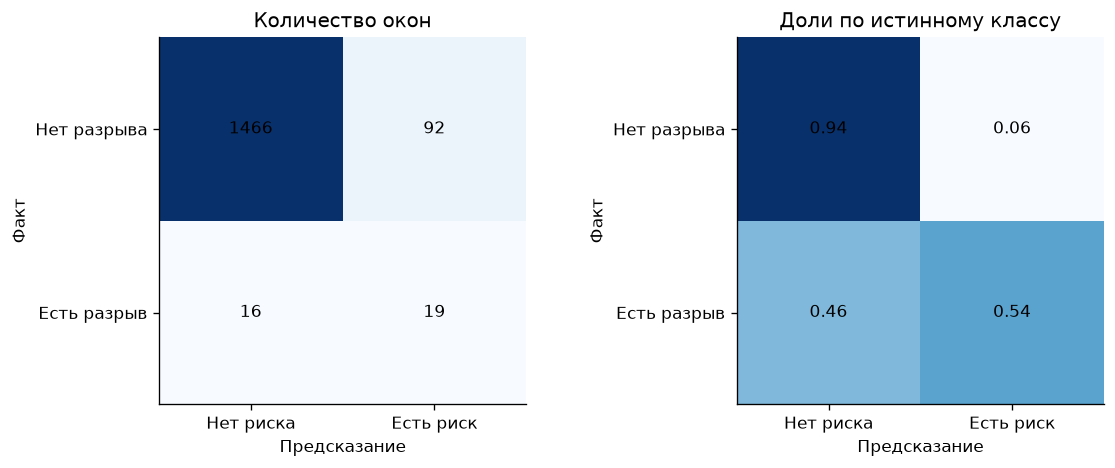

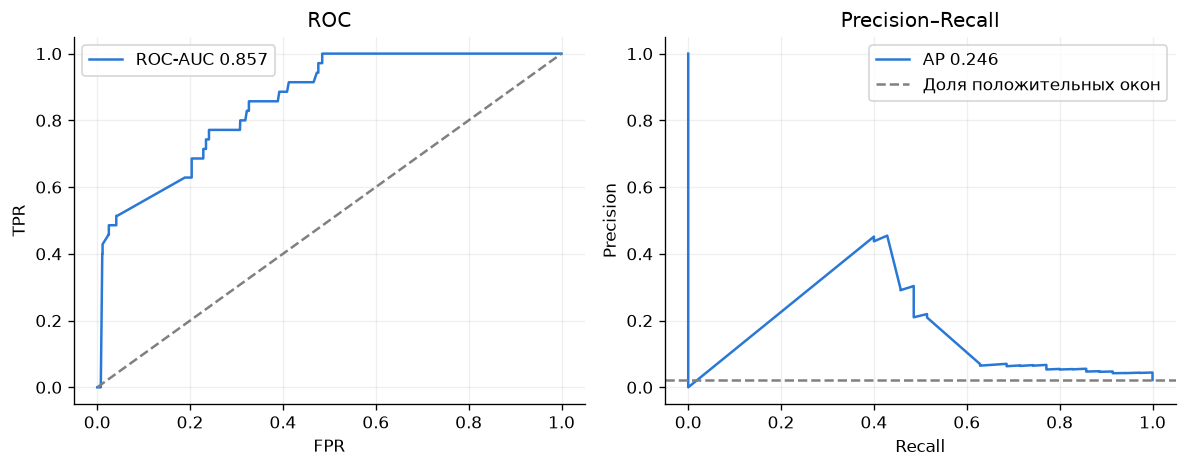

In [7]:
W['score']=[p['score'] for p in OOF]; W['threshold']=[p['threshold'] for p in OOF]
W['prediction']=W['score']>=W['threshold']
C=W[~W['ongoing']].copy()
assert len(C) and C['gap_actual'].nunique()==2,'В тесте нужны оба класса; увеличьте число компаний/окон'
y=C['gap_actual'].to_numpy(bool); score=C['score'].to_numpy(float); pred=C['prediction'].to_numpy(bool)
def classification_metrics(y,score,pred):
    return dict(precision=float(precision_score(y,pred,zero_division=0)),
        recall=float(recall_score(y,pred,zero_division=0)),f1=float(f1_score(y,pred,zero_division=0)),
        accuracy=float(accuracy_score(y,pred)),roc_auc=float(roc_auc_score(y,score)),
        pr_auc=float(average_precision_score(y,score)),brier=float(brier_score_loss(y,score)))
RISK_METRICS=classification_metrics(y,score,pred)
CM=confusion_matrix(y,pred,labels=[False,True])
RISK_METRICS.update(windows=len(C),positives=int(y.sum()),positive_rate=float(y.mean()),
                    confusion_matrix=CM.tolist(),excluded_ongoing=int(W['ongoing'].sum()))
print(json.dumps(RISK_METRICS,ensure_ascii=False,indent=2))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,values,title in zip(axes,[CM,CM/np.maximum(CM.sum(axis=1,keepdims=True),1)],['Количество окон','Доли по истинному классу']):
    image=ax.imshow(values,cmap='Blues'); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j,i,f'{values[i,j]:.2f}' if values.dtype.kind=='f' else str(values[i,j]),ha='center',va='center')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Нет риска','Есть риск'],yticklabels=['Нет разрыва','Есть разрыв'],
           xlabel='Предсказание',ylabel='Факт',title=title)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrices.png',dpi=160); plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,4))
fpr,tpr,_=roc_curve(y,score); precision,recall,_=precision_recall_curve(y,score)
axes[0].plot(fpr,tpr,color='#2a78d6',label=f"ROC-AUC {RISK_METRICS['roc_auc']:.3f}")
axes[0].plot([0,1],[0,1],'--',color='gray'); axes[0].set(xlabel='FPR',ylabel='TPR',title='ROC')
axes[1].plot(recall,precision,color='#2a78d6',label=f"AP {RISK_METRICS['pr_auc']:.3f}")
axes[1].axhline(y.mean(),ls='--',color='gray',label='Доля положительных окон')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall')
for ax in axes: ax.legend()
plt.tight_layout(); plt.savefig(OUT/'roc_pr.png',dpi=160); plt.show()



## 7. Ошибка остатка: рубли и единицы масштаба
Наивный ориентир — текущий остаток не меняется; это только контроль качества, не модель продукта.
relative_MAE_to_flat — отношение MAE CatBoost к MAE этого ориентира, НЕ стандартный time-series MASE.
Интервал P10–P90 должен покрывать около 80% фактов; отклонение показываем честно.



 horizon     rmse_rub      mae_rub  rmse_scale  mae_scale     bias_rub  flat_mae_rub  relative_MAE_to_flat  coverage_p10_p90  mean_width_rub
       5 3386930.2598 1152798.0097      6.2405     2.8242   30749.3536  1128841.3855                1.0212            0.7591    3060754.7911
      10 4117289.9600 1473783.7804      7.4568     3.6572 -103894.6504  1493574.7334                0.9867            0.7312    3732726.6155
      20 5017003.1608 1870025.6145     11.5231     4.8757 -338812.0218  1857209.5728                1.0069            0.7215    4235937.4182
      30 5696886.0416 2136958.5742     15.1293     6.0517 -426433.4492  2165268.1526                0.9869            0.6768    4448106.1187


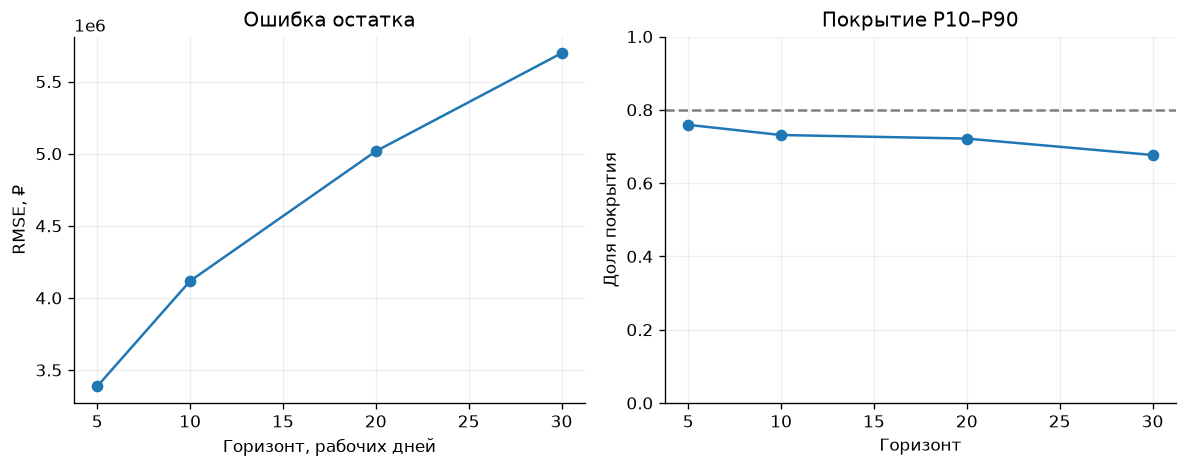

In [8]:
REG_ROWS=[]
for h in [5,10,20,30]:
    errors=np.array([p['mean'][h-1]-w['actual'][h-1] for p,(_,w) in zip(OOF,W.iterrows())])
    scales=np.array([p['scale'] for p in OOF])
    flat=np.array([w['bal0']-w['actual'][h-1] for _,w in W.iterrows()])
    q10,q90=QS.index(.1),QS.index(.9)
    coverage=np.mean([p['q'][h-1,q10]<=w['actual'][h-1]<=p['q'][h-1,q90] for p,(_,w) in zip(OOF,W.iterrows())])
    baseline_mae=float(np.mean(np.abs(flat)))
    REG_ROWS.append(dict(horizon=h,rmse_rub=float(np.sqrt(np.mean(errors**2))),mae_rub=float(np.mean(abs(errors))),
        rmse_scale=float(np.sqrt(np.mean((errors/scales)**2))),mae_scale=float(np.mean(abs(errors/scales))),
        bias_rub=float(errors.mean()),flat_mae_rub=baseline_mae,
        relative_MAE_to_flat=float(np.mean(abs(errors))/baseline_mae) if baseline_mae else None,
        coverage_p10_p90=float(coverage),mean_width_rub=float(np.mean([p['q'][h-1,q90]-p['q'][h-1,q10] for p in OOF]))))
REGRESSION=pd.DataFrame(REG_ROWS)
print(REGRESSION.round(4).to_string(index=False))
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot(REGRESSION['horizon'],REGRESSION['rmse_rub'],'o-',label='CatBoost RMSE')
axes[0].set(xlabel='Горизонт, рабочих дней',ylabel='RMSE, ₽',title='Ошибка остатка')
axes[1].plot(REGRESSION['horizon'],REGRESSION['coverage_p10_p90'],'o-')
axes[1].axhline(.8,ls='--',color='gray'); axes[1].set(xlabel='Горизонт',ylabel='Доля покрытия',ylim=(0,1),title='Покрытие P10–P90')
plt.tight_layout(); plt.savefig(OUT/'regression_coverage.png',dpi=160); plt.show()



## 8. Условная ошибка даты и суммы: только найденные положительные окна
Это НЕ полноценное сопоставление эпизодов. Дата — первое превышение фиксированного
CFG['day_risk_threshold']=0.2 дневной вероятностью из квантилей, не порога классификатора;
сумма — максимум нехватки по точечному RMSE-прогнозу против факта на горизонте.
Отрицательная ошибка даты означает более ранний прогноз. Не маскируем пропущенные окна: их учитывает recall выше.



In [9]:
gap_rows=[]
for i,w in C.iterrows():
    p=OOF[i]
    if not(w['gap_actual'] and w['prediction']): continue
    actual_days=np.flatnonzero(w['actual']<0); predicted_days=np.flatnonzero(p['prob']>=CFG['day_risk_threshold'])
    if not len(predicted_days): continue
    true_amount=float(max(0.,-w['actual'].min())); predicted_amount=float(max(0.,-p['mean'].min()))
    delta=int(predicted_days[0]-actual_days[0])
    gap_rows.append(dict(company=w['company'],cutoff=str(w['cutoff'].date()),date_error_wd=delta,
        first_actual_wd=int(actual_days[0]+1),first_predicted_wd=int(predicted_days[0]+1),
        actual_shortfall_rub=true_amount,predicted_shortfall_rub=predicted_amount,
        amount_abs_error_rub=abs(predicted_amount-true_amount),amount_abs_error_scale=abs(predicted_amount-true_amount)/p['scale'],
        amount_relative_error=abs(predicted_amount-true_amount)/max(true_amount,1.)))
GAPS=pd.DataFrame(gap_rows)
GAP_METRICS={'matched_positive_windows':len(GAPS),
    'classifier_true_positive_windows':int((C['gap_actual']&C['prediction']).sum()),
    'date_rule':'first quantile day probability >= fixed day_risk_threshold',
    'day_risk_threshold':CFG['day_risk_threshold']}
if len(GAPS):
    GAP_METRICS.update(date_mae_wd=float(GAPS['date_error_wd'].abs().mean()),date_median_error_wd=float(GAPS['date_error_wd'].median()),
        date_within_2_wd=float(GAPS['date_error_wd'].abs().le(2).mean()),date_within_5_wd=float(GAPS['date_error_wd'].abs().le(5).mean()),
        shortfall_mae_rub=float(GAPS['amount_abs_error_rub'].mean()),shortfall_mae_scale=float(GAPS['amount_abs_error_scale'].mean()),
        shortfall_median_relative_error=float(GAPS['amount_relative_error'].median()))
print(json.dumps(GAP_METRICS,ensure_ascii=False,indent=2))



{
  "matched_positive_windows": 10,
  "classifier_true_positive_windows": 19,
  "date_rule": "first quantile day probability >= fixed day_risk_threshold",
  "day_risk_threshold": 0.2,
  "date_mae_wd": 7.9,
  "date_median_error_wd": -1.0,
  "date_within_2_wd": 0.4,
  "date_within_5_wd": 0.4,
  "shortfall_mae_rub": 1057518.4964296864,
  "shortfall_mae_scale": 2.713427626901411,
  "shortfall_median_relative_error": 1.0
}


## 9. Неопределённость, обучение и признаки
Бутстреп пересэмплирует компании целиком: перекрывающиеся окна одной компании зависимы.
Интервалы условны на уже обученные модели и выбранные validation-пороги, не включают разброс переобучения.



95% интервалы по компаниям: {
  "precision": [
    0.034175920514319114,
    0.3201640625
  ],
  "recall": [
    0.1868006993006993,
    0.8248721227621483
  ],
  "f1": [
    0.05631955484896662,
    0.4300358422939066
  ],
  "accuracy": [
    0.9062959075986134,
    0.9588432021529097
  ],
  "roc_auc": [
    0.6958415763856178,
    0.9490466373097867
  ],
  "pr_auc": [
    0.03018611585604754,
    0.45635920945347763
  ],
  "brier": [
    0.041349345021899964,
    0.06686482305981471
  ]
}


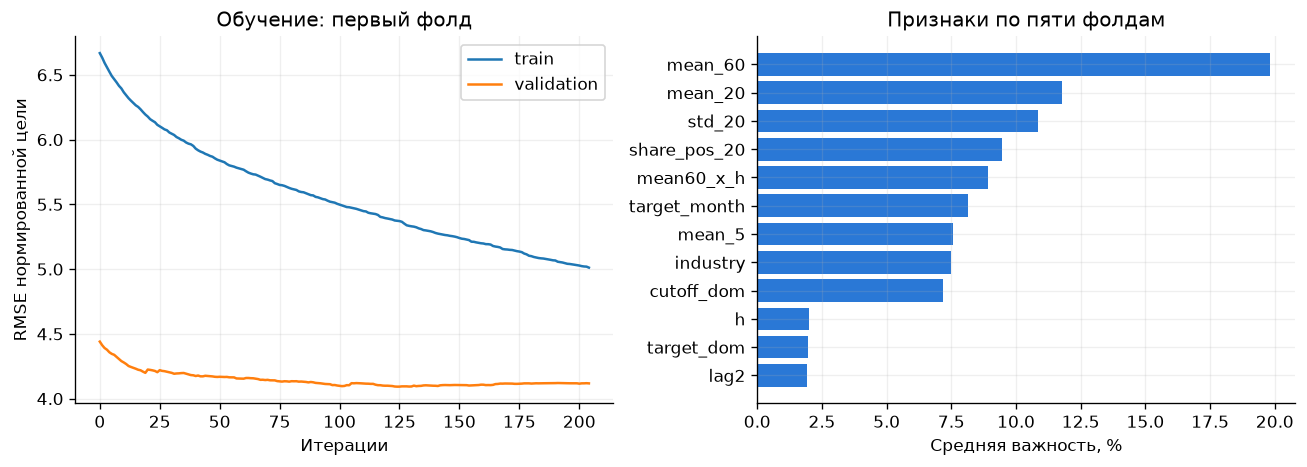

In [10]:
rng=np.random.default_rng(CFG['seed']); groups=[g.index.to_numpy() for _,g in C.groupby('company')]
bootstrap=[]
for _ in range(CFG['bootstrap']):
    ids=np.concatenate([groups[j] for j in rng.integers(0,len(groups),len(groups))]); sample=W.loc[ids]
    if sample['gap_actual'].nunique()<2: continue
    bootstrap.append(classification_metrics(sample['gap_actual'],sample['score'],sample['prediction']))
CI={k:np.percentile([r[k] for r in bootstrap],[2.5,97.5]).tolist() for k in RISK_METRICS if bootstrap and k in bootstrap[0]}
print('95% интервалы по компаниям:',json.dumps(CI,ensure_ascii=False,indent=2))
IMPORTANCE=pd.DataFrame({'feature':FEATURES,'importance':np.mean(IMPORTANCES,axis=0)}).sort_values('importance',ascending=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
curve=CURVES[0]; axes[0].plot(curve['learn']['RMSE'],label='train'); axes[0].plot(curve['validation']['RMSE'],label='validation')
axes[0].set(xlabel='Итерации',ylabel='RMSE нормированной цели',title='Обучение: первый фолд'); axes[0].legend()
top=IMPORTANCE.head(12).iloc[::-1]; axes[1].barh(top['feature'],top['importance'],color='#2a78d6')
axes[1].set(xlabel='Средняя важность, %',title='Признаки по пяти фолдам')
plt.tight_layout(); plt.savefig(OUT/'training_importance.png',dpi=160); plt.show()



## 10. Модель в работе: один отложенный пример
Для наглядности выбирается первое найденное положительное окно, иначе первое положительное,
иначе первое тестовое. Это иллюстрация, не отдельное доказательство качества; итоговые метрики — по всем окнам.



Этот пример не использовался для обучения или выбора порога своего фолда.


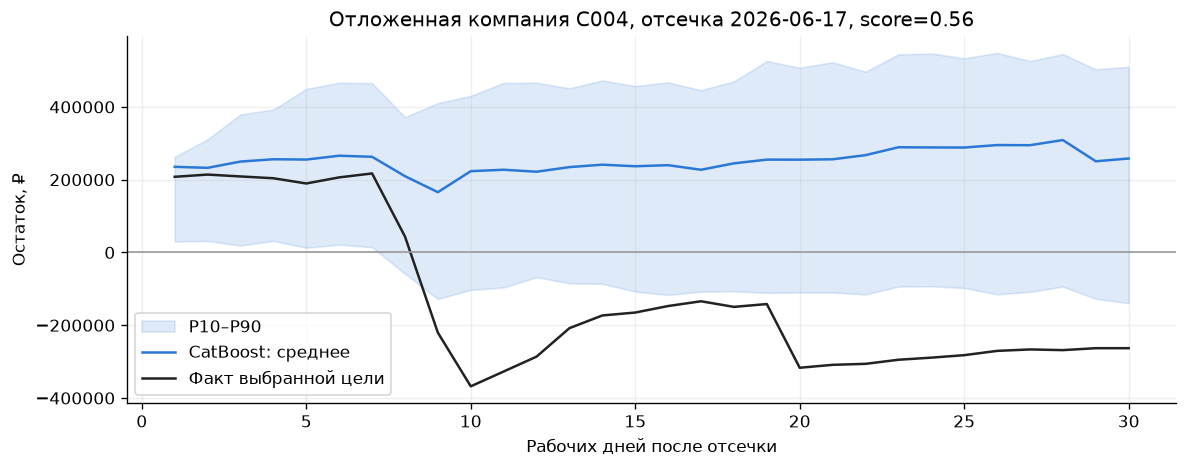

In [11]:
candidate=C[C['gap_actual']&C['prediction']]
if candidate.empty: candidate=C[C['gap_actual']]
if candidate.empty: candidate=C
example_index=int(candidate.index[0]); w=W.loc[example_index]; p=OOF[example_index]
days=np.arange(1,H+1)
fig,ax=plt.subplots(figsize=(10,4))
ax.fill_between(days,p['q'][:,QS.index(.1)],p['q'][:,QS.index(.9)],color='#2a78d6',alpha=.15,label='P10–P90')
ax.plot(days,p['mean'],color='#2a78d6',label='CatBoost: среднее')
ax.plot(days,w['actual'],color='#222222',label='Факт выбранной цели')
ax.axhline(0,color='#999999',lw=1); ax.set(xlabel='Рабочих дней после отсечки',ylabel='Остаток, ₽',
    title=f"Отложенная компания {w['company']}, отсечка {w['cutoff'].date()}, score={p['score']:.2f}")
ax.legend(); plt.tight_layout(); plt.savefig(OUT/'heldout_example.png',dpi=160); plt.show()
print('Этот пример не использовался для обучения или выбора порога своего фолда.')



## 11. Сохранение результата и ограничения
Экспортируются свежие метрики, OOF-прогнозы, модели всех фолдов и конфигурация.
Не заявляйте победу над ориентиром, если relative_MAE_to_flat >= 1.
Источник — синтетический кейс; результат не доказывает качество на реальных банковских клиентах.
Отдельный классификатор категорий здесь не обучается: confusion matrix относится к риску разрыва.
Проверка календаря использует даты исходного кейса; модель оценивается на доступной истории, не на будущих годах.
Изменения гиперпараметров после просмотра результатов потребуют нового нетронутого holdout.



In [12]:
def clean_json(value):
    if isinstance(value,dict): return {str(k):clean_json(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)): return [clean_json(v) for v in value]
    if isinstance(value,np.generic): value=value.item()
    if isinstance(value,float) and not np.isfinite(value): return None
    return value
METRICS=dict(created_at=datetime.now(timezone.utc).isoformat(),archive_sha256=archive_sha256,config=CFG,
    target_definition=('операционный остаток: исключены будущие owner/transfer/financing' if CFG['target']=='operational' else 'полный банковский остаток'),
    protocol=dict(company_folds=CFG['n_folds'],eval_start=str(EVAL_START.date()),
        threshold='только отдельные validation-компании, цели до eval_start',classification_unit='компания × отсечка × 30 рабочих дней',
        score='CatBoostClassifier direct window target; Balanced class weights; not probability-calibrated',
        risk_source='risk_classifier',day_risk_threshold=CFG['day_risk_threshold']),
    risk=RISK_METRICS,risk_ci95=CI,regression=REGRESSION.to_dict('records'),gaps=GAP_METRICS,
    seconds=round(time.time()-STARTED,2),versions=dict(python=sys.version,numpy=np.__version__,pandas=pd.__version__))
(OUT/'metrics.json').write_text(json.dumps(clean_json(METRICS),ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
FOLDS.to_csv(OUT/'folds.csv',index=False); REGRESSION.to_csv(OUT/'regression.csv',index=False)
IMPORTANCE.to_csv(OUT/'feature_importance.csv',index=False); GAPS.to_csv(OUT/'gap_errors.csv',index=False)
W[['company','cutoff','fold','bal0','gap_actual','ongoing','score','threshold','prediction']].to_csv(OUT/'oof_windows.csv',index=False)
paths=[]
for i,w in W.iterrows():
    p=OOF[i]
    for j in range(H):
        paths.append(dict(company=w['company'],cutoff=str(w['cutoff'].date()),h=j+1,date=str(w['dates'][j].date()),
            actual=float(w['actual'][j]),actual_cash=float(w['actual_cash'][j]),mean=float(p['mean'][j]),
            p10=float(p['q'][j,QS.index(.1)]),p50=float(p['q'][j,QS.index(.5)]),p90=float(p['q'][j,QS.index(.9)]),prob=float(p['prob'][j])))
pd.DataFrame(paths).to_csv(OUT/'oof_paths.csv',index=False)
(OUT/'model_metadata.json').write_text(json.dumps(dict(features=FEATURES,risk_features=RISK_FEATURES,
    risk_source='risk_classifier',cat_features=CAT_FEATURES,quantiles=QS,
    fold_thresholds={str(x['fold']):x['threshold'] for x in FOLD_LOG},config=CFG),ensure_ascii=False,indent=2),encoding='utf-8')
print('Готово:',OUT,'\nВремя:',METRICS['seconds'],'секунд')
print('Финальные метрики:',json.dumps(clean_json(RISK_METRICS),ensure_ascii=False,indent=2))


Готово: D:\!finance\ledokol_tmp\analytics\mentor_catboost_output 
Время: 224.61 секунд
Финальные метрики: {
  "precision": 0.17117117117117117,
  "recall": 0.5428571428571428,
  "f1": 0.2602739726027397,
  "accuracy": 0.9322033898305084,
  "roc_auc": 0.8574912891986063,
  "pr_auc": 0.245838643483274,
  "brier": 0.053334744240772565,
  "windows": 1593,
  "positives": 35,
  "positive_rate": 0.02197112366603892,
  "confusion_matrix": [
    [
      1466,
      92
    ],
    [
      16,
      19
    ]
  ],
  "excluded_ongoing": 59
}


## Короткий итог простыми словами
Числа рассчитаны текущим запуском. Для редких разрывов смотрите precision и recall, а не только accuracy.


In [13]:
risk = METRICS['risk']
tn, fp = risk['confusion_matrix'][0]
fn, tp = risk['confusion_matrix'][1]
h30 = next(row for row in METRICS['regression'] if row['horizon'] == 30)
print(f"Проверено {risk['windows']} окон, в {risk['positives']} фактически не хватило денег.")
print(f"CatBoost нашёл {tp} из {risk['positives']} таких окон, пропустил {fn}; ложных тревог: {fp}.")
print(f"Верных среди предупреждений: {risk['precision']:.1%}. Найдено среди всех проблем: {risk['recall']:.1%}.")
print(f"F1: {risk['f1']:.3f}; ROC-AUC: {risk['roc_auc']:.3f}; PR-AUC: {risk['pr_auc']:.3f}.")
print(f"На 30-й день отношение MAE к простому прогнозу: {h30['relative_MAE_to_flat']:.3f} (меньше 1 — лучше).")
print(f"Диапазон P10–P90 покрыл {h30['coverage_p10_p90']:.1%} фактических значений вместо желательных 80%.")
print("Это проверка на синтетическом кейсе, а не подтверждение качества на реальных клиентах.")
print("Разработочная CV не заменяет финальную проверку выбранной модели на новом нетронутом наборе.")


Проверено 1593 окон, в 35 фактически не хватило денег.
CatBoost нашёл 19 из 35 таких окон, пропустил 16; ложных тревог: 92.
Верных среди предупреждений: 17.1%. Найдено среди всех проблем: 54.3%.
F1: 0.260; ROC-AUC: 0.857; PR-AUC: 0.246.
На 30-й день отношение MAE к простому прогнозу: 0.987 (меньше 1 — лучше).
Диапазон P10–P90 покрыл 67.7% фактических значений вместо желательных 80%.
Это проверка на синтетическом кейсе, а не подтверждение качества на реальных клиентах.
Разработочная CV не заменяет финальную проверку выбранной модели на новом нетронутом наборе.
